# Decision Trees & Random Forests: Heart Disease Classification

**Objective:** Learn tree-based models for classification (and regression): how a single tree learns, why it overfits, and how a Random Forest fixes that.
**Tools:** Scikit-learn, Graphviz (+ Pandas, NumPy, Matplotlib, Seaborn)
**Dataset:** Heart Disease dataset (13 clinical features, binary `target`).

## Workflow
1. Load, clean and explore the data
2. Train a Decision Tree and **visualize** it (Matplotlib + Graphviz)
3. **Analyze overfitting** and control it with tree depth, pruning and grid search
4. Entropy and information gain (worked example)
5. Train a **Random Forest** and compare accuracy
6. Interpret **feature importances** (impurity-based and permutation)
7. Evaluate with **repeated cross-validation**
8. Bonus: tree models for **regression**
9. Key concepts Q&A

## 1. Imports & Setup

In [1]:
import os, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold, KFold,
                                     RepeatedStratifiedKFold, cross_val_score, cross_validate)
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree,
                          export_graphviz, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_squared_error, mean_absolute_error)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RS = 42
C_DT, C_RF, C_ACC, C_RED, C_GREEN = "#2E86AB", "#4C9F70", "#8E5572", "#D1495B", "#F2A541"

# Output folder (Kaggle -> /kaggle/working, otherwise local ./outputs)
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
os.makedirs(OUT, exist_ok=True)
print("Outputs will be saved to:", OUT)

Outputs will be saved to: /kaggle/working


## 2. Load the Dataset

On Kaggle, click **Add Input** and add a *Heart Disease Dataset* (the CSV with columns `age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal, target`). The cell below finds it automatically.

In [2]:
df, DATA_SOURCE = None, None
needed = {"age", "sex", "cp", "chol", "thalach", "target"}

search_paths = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob("./data/*.csv") + glob.glob("./*.csv")
for path in search_paths:
    try:
        tmp = pd.read_csv(path, encoding="utf-8-sig")
    except Exception:
        continue
    tmp.columns = [c.strip() for c in tmp.columns]
    if needed.issubset(tmp.columns):
        df, DATA_SOURCE = tmp, path
        break

if df is None:
    raise FileNotFoundError(
        "Heart Disease CSV not found. On Kaggle: click 'Add Input' -> search 'Heart Disease Dataset' -> Add, "
        "then run again. Locally: put the CSV in ./data/.")

print("Data source:", DATA_SOURCE)
print("Shape:", df.shape)
df.head()

Data source: /kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv
Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


| Feature | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | Sex (1 = male, 0 = female) |
| `cp` | Chest pain type (coded 0-3) |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true) |
| `restecg` | Resting ECG result (coded 0-2) |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes) |
| `oldpeak` | ST depression induced by exercise |
| `slope` | Slope of the peak exercise ST segment |
| `ca` | Number of major vessels coloured by fluoroscopy (0-4) |
| `thal` | Thalassemia test result (coded) |
| `target` | Binary outcome (0 / 1) |

## 3. Explore & Clean the Data

In [3]:
print("Missing values:", int(df.isnull().sum().sum()))
n_dup = int(df.duplicated().sum())
print("Duplicate rows:", n_dup)
df.info()

Missing values: 0
Duplicate rows: 723
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


**Why duplicates matter for trees:** if identical rows exist, copies of the same patient can land in *both* the training and the test set. A deep tree simply memorises them, and the test accuracy becomes unrealistically high (data leakage). Some public copies of this dataset contain hundreds of duplicates, so we always drop them first.

Rows after removing duplicates: 302
target
0    138
1    164 

target
0    45.7 %
1    54.3 %
Name: count, dtype: object


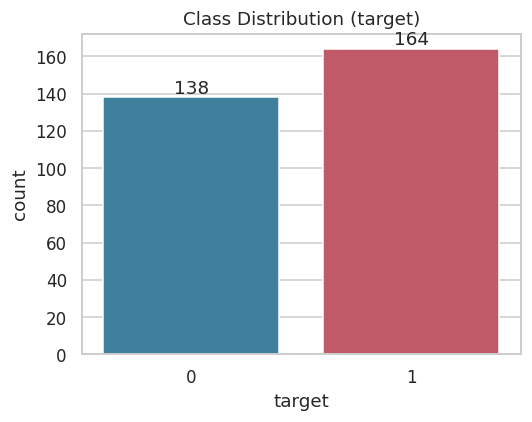

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

features = [c for c in df.columns if c != "target"]
X, y = df[features], df["target"].astype(int)

counts = y.value_counts().sort_index()
print(counts.to_string(), "\n")
print((counts / len(y) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=y, palette=[C_DT, C_RED], ax=ax)
ax.set_title("Class Distribution (target)")
ax.set_xlabel("target")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig(f"{OUT}/01_class_distribution.png", bbox_inches="tight")
plt.show()

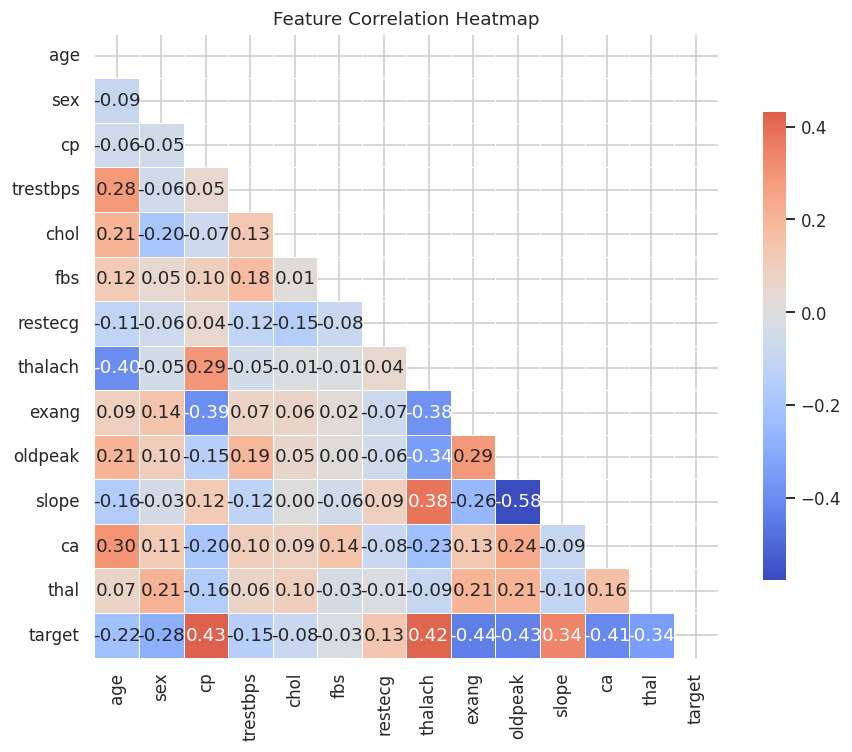

Correlation with target:
exang      -0.44
oldpeak    -0.43
ca         -0.41
thal       -0.34
sex        -0.28
age        -0.22
trestbps   -0.15
chol       -0.08
fbs        -0.03
restecg     0.13
slope       0.34
thalach     0.42
cp          0.43


In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=.5, cbar_kws={"shrink": .75}, ax=ax)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{OUT}/02_correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Correlation with target:")
print(corr["target"].drop("target").sort_values().round(2).to_string())

> **Note on the label:** in this copy of the data, `target = 1` goes together with a *higher* maximum heart rate (`thalach`) and *no* exercise-induced angina (`exang`), which clinically points to lower cardiac risk, while descriptions of this dataset commonly say `1 = disease`. Several public copies are reported to use the label either way round, so we do not make clinical claims here and simply call the two classes **target 0** and **target 1**. This does not affect any model or metric: trees and all scores behave identically if the two labels are swapped.

Trees also do not need feature scaling, because each split only compares one feature with a threshold. So, unlike logistic regression, we skip `StandardScaler`.

## 4. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("target=1 share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (241, 13) | Test: (61, 13)
target=1 share  train: 0.544  test: 0.541


## 5. Decision Tree: Training & Visualization

A decision tree learns a sequence of yes/no questions (`feature <= threshold?`). At every node it picks the split that makes the child nodes as *pure* as possible, measured by **Gini impurity** or **entropy**. If we let it grow with no limits it keeps splitting until every training sample is classified perfectly.

In [7]:
dt_full = DecisionTreeClassifier(random_state=RS).fit(X_train, y_train)

print("Unrestricted tree -> depth:", dt_full.get_depth(), "| leaves:", dt_full.get_n_leaves())
print("Train accuracy: %.4f" % dt_full.score(X_train, y_train))
print("Test  accuracy: %.4f" % dt_full.score(X_test, y_test))

Unrestricted tree -> depth: 9 | leaves: 35
Train accuracy: 1.0000
Test  accuracy: 0.8033


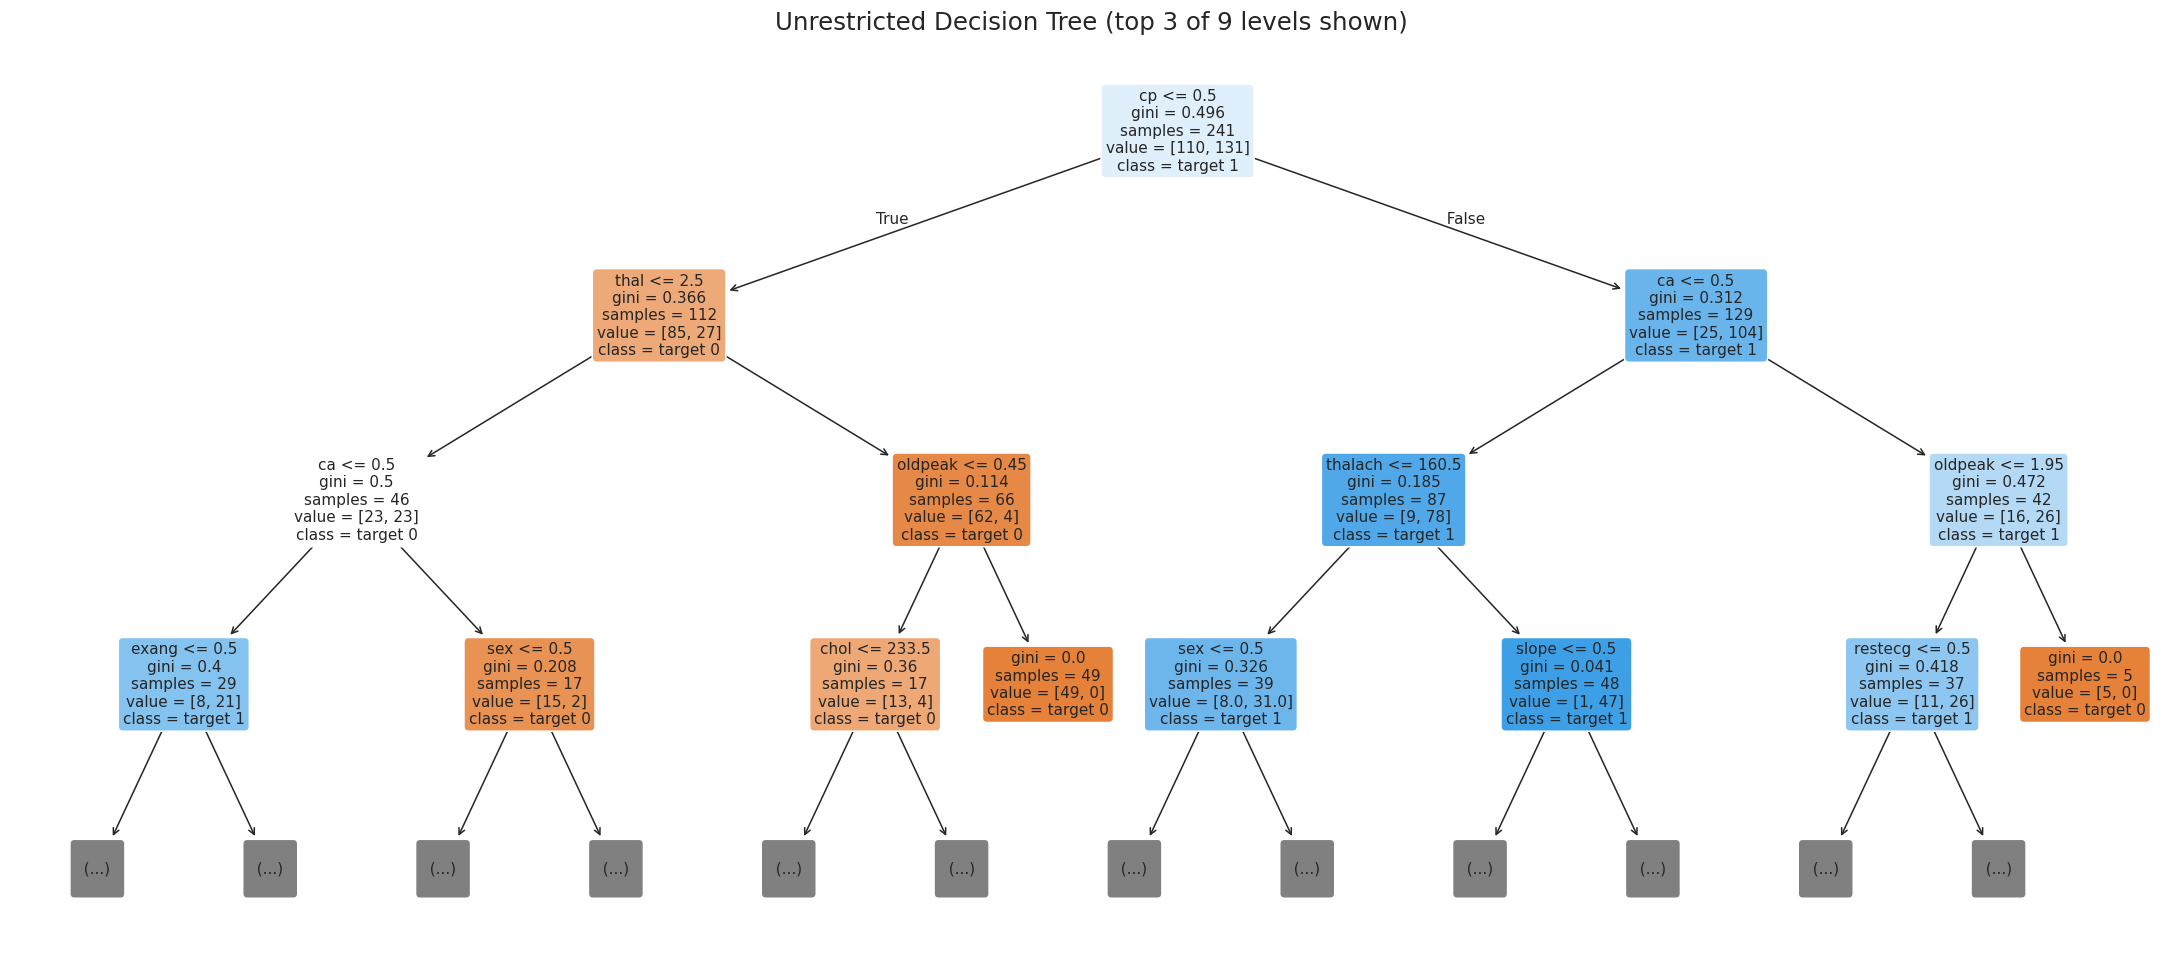

In [8]:
# Visualize the first 3 levels of the unrestricted tree (the full tree is far too large to read)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(dt_full, max_depth=3, feature_names=features, class_names=["target 0", "target 1"],
          filled=True, rounded=True, fontsize=10, proportion=False, ax=ax)
ax.set_title(f"Unrestricted Decision Tree (top 3 of {dt_full.get_depth()} levels shown)", fontsize=16)
plt.tight_layout()
plt.savefig(f"{OUT}/03_unrestricted_tree_top_levels.png", bbox_inches="tight")
plt.show()

**Observation:** the tree reaches 100% training accuracy but a clearly lower test accuracy. That gap is **overfitting**: the tree has memorised the training data, including its noise, instead of learning general rules.

## 6. Analyzing Overfitting & Controlling Tree Depth

We train trees of increasing `max_depth` and track three scores:
- **Train accuracy** (always climbs)
- **Cross-validated accuracy** on the training set (honest estimate used to choose the depth)
- **Test accuracy** (held out, only for reporting)

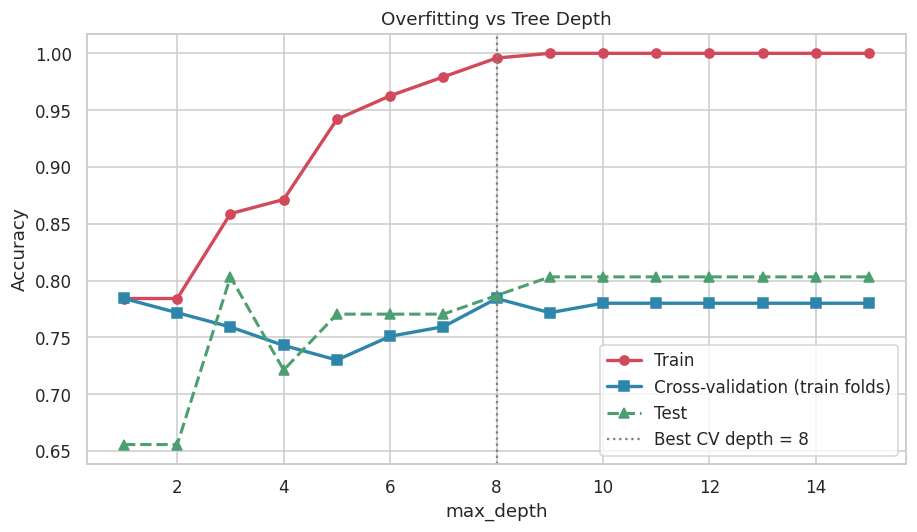

Best depth by cross-validation: 8


,max_depth,train,cv,test
0,1,0.7842,0.7843,0.6557
1,2,0.7842,0.7718,0.6557
2,3,0.8589,0.7592,0.8033
3,4,0.8714,0.7429,0.7213
4,5,0.9419,0.7301,0.7705
5,6,0.9627,0.7510,0.7705
6,7,0.9793,0.7594,0.7705
7,8,0.9959,0.7843,0.7869
8,9,1.0000,0.7718,0.8033
9,10,1.0000,0.7801,0.8033


In [9]:
rows = []
for d in range(1, 16):
    t = DecisionTreeClassifier(max_depth=d, random_state=RS)
    cv_acc = cross_val_score(t, X_train, y_train, cv=skf5, scoring="accuracy").mean()
    t.fit(X_train, y_train)
    rows.append({"max_depth": d, "train": t.score(X_train, y_train), "cv": cv_acc, "test": t.score(X_test, y_test)})
depth_df = pd.DataFrame(rows)
best_depth = int(depth_df.loc[depth_df["cv"].idxmax(), "max_depth"])

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(depth_df["max_depth"], depth_df["train"], "o-", color=C_RED, lw=2.2, label="Train")
ax.plot(depth_df["max_depth"], depth_df["cv"], "s-", color=C_DT, lw=2.2, label="Cross-validation (train folds)")
ax.plot(depth_df["max_depth"], depth_df["test"], "^--", color=C_RF, lw=2, label="Test")
ax.axvline(best_depth, color="gray", ls=":", label=f"Best CV depth = {best_depth}")
ax.set_xlabel("max_depth"); ax.set_ylabel("Accuracy")
ax.set_title("Overfitting vs Tree Depth")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/04_overfitting_vs_depth.png", bbox_inches="tight")
plt.show()

print("Best depth by cross-validation:", best_depth)
depth_df.round(4)

**Reading the chart:** train accuracy keeps rising with depth, while cross-validation and test accuracy peak at a shallow depth and then flatten or drop. Where train and validation scores diverge, the model is overfitting.

### Cost-complexity pruning (`ccp_alpha`)
Another way to control the size of a tree is **post-pruning**: grow the full tree, then remove branches that add little. A larger `ccp_alpha` prunes more.

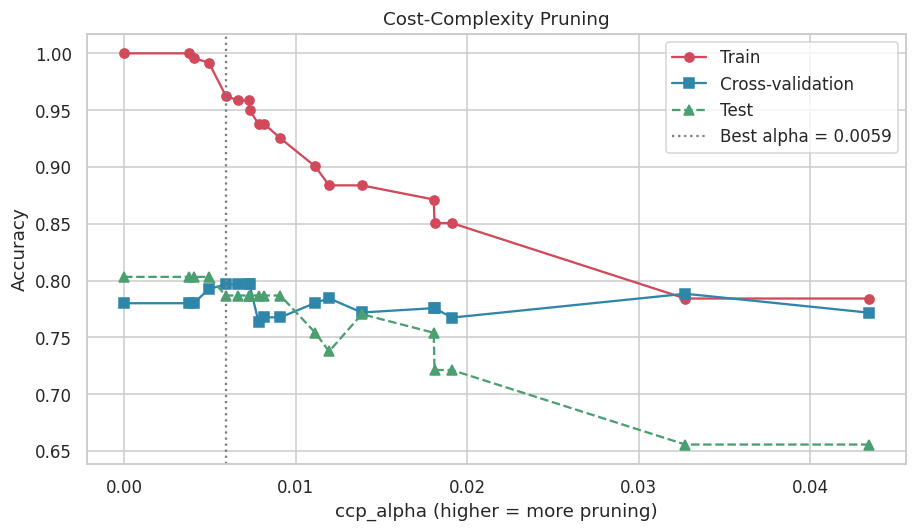

Best ccp_alpha by cross-validation: 0.00593


In [10]:
path = DecisionTreeClassifier(random_state=RS).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas, 5))[:-1]      # last alpha would prune everything to the root

rows = []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=RS)
    cv_acc = cross_val_score(t, X_train, y_train, cv=skf5).mean()
    t.fit(X_train, y_train)
    rows.append({"ccp_alpha": a, "train": t.score(X_train, y_train), "cv": cv_acc,
                 "test": t.score(X_test, y_test), "leaves": t.get_n_leaves()})
ccp_df = pd.DataFrame(rows)
best_alpha = float(ccp_df.loc[ccp_df["cv"].idxmax(), "ccp_alpha"])

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(ccp_df["ccp_alpha"], ccp_df["train"], "o-", color=C_RED, label="Train")
ax.plot(ccp_df["ccp_alpha"], ccp_df["cv"], "s-", color=C_DT, label="Cross-validation")
ax.plot(ccp_df["ccp_alpha"], ccp_df["test"], "^--", color=C_RF, label="Test")
ax.axvline(best_alpha, color="gray", ls=":", label=f"Best alpha = {best_alpha:.4f}")
ax.set_xlabel("ccp_alpha (higher = more pruning)"); ax.set_ylabel("Accuracy")
ax.set_title("Cost-Complexity Pruning")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/05_pruning_path.png", bbox_inches="tight")
plt.show()
print("Best ccp_alpha by cross-validation:", best_alpha)

## 7. Hyperparameter Tuning (Grid Search)

We search over the split criterion, depth, minimum samples per leaf and pruning strength, using **5-fold cross-validation on the training set only**.

In [11]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "ccp_alpha": [0.0, 0.005, 0.01, 0.02],
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RS), param_grid, cv=skf5,
                       scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
dt_tuned = dt_grid.best_estimator_

print("Best params :", dt_grid.best_params_)
print("Best CV acc : %.4f" % dt_grid.best_score_)
print("Tuned tree  -> depth: %d | leaves: %d" % (dt_tuned.get_depth(), dt_tuned.get_n_leaves()))
print("Train accuracy: %.4f" % dt_tuned.score(X_train, y_train))
print("Test  accuracy: %.4f" % dt_tuned.score(X_test, y_test))

Best params : {'ccp_alpha': 0.02, 'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 10}
Best CV acc : 0.8132
Tuned tree  -> depth: 3 | leaves: 7
Train accuracy: 0.8382
Test  accuracy: 0.7705


## 8. Visualizing the Tuned Tree

Two ways to visualize a tree:
1. `sklearn.tree.plot_tree` (Matplotlib, no extra install)
2. `export_graphviz` + **Graphviz** (publication-quality, also saved as a `.dot` file)

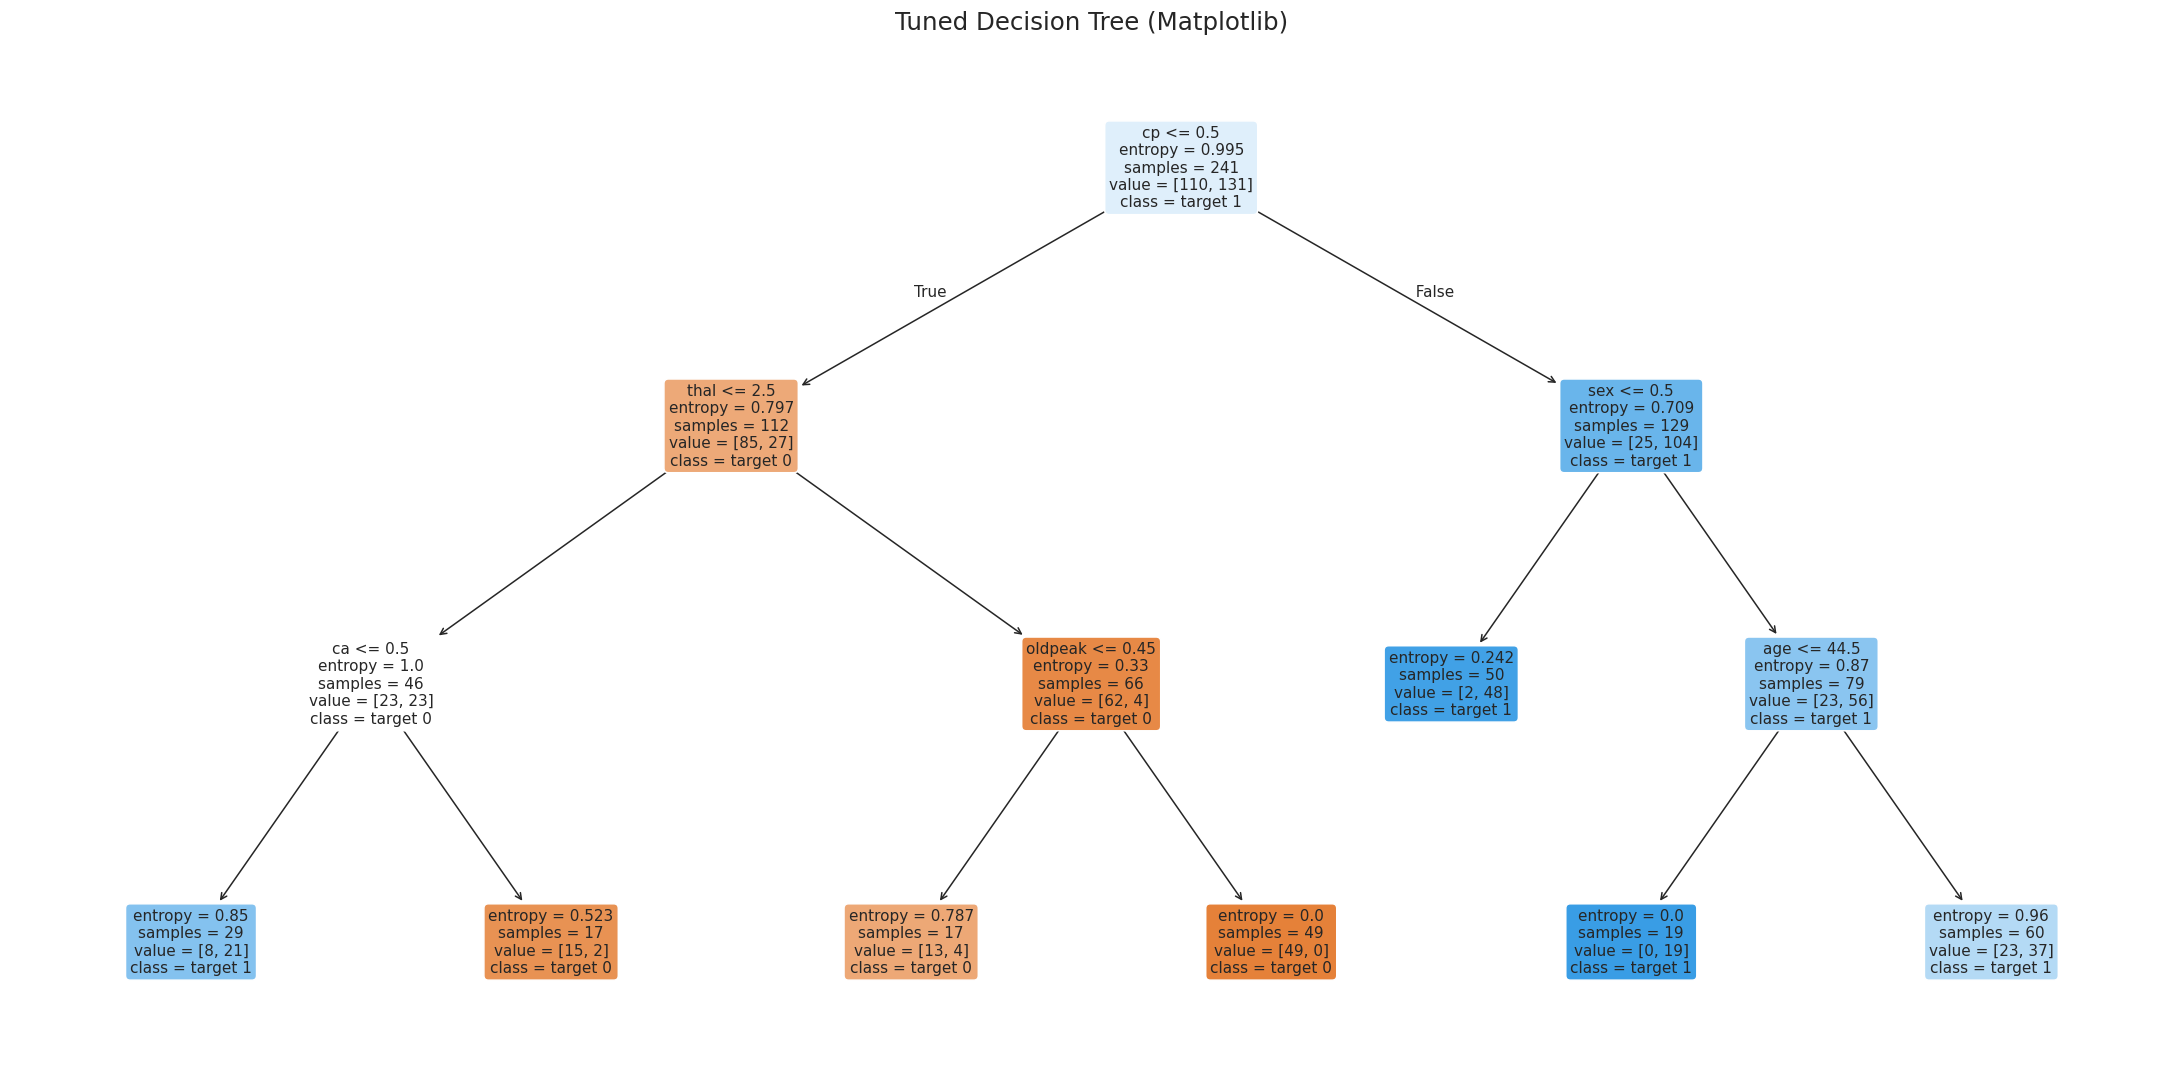

In [12]:
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(dt_tuned, feature_names=features, class_names=["target 0", "target 1"],
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("Tuned Decision Tree (Matplotlib)", fontsize=16)
plt.tight_layout()
plt.savefig(f"{OUT}/06_tuned_tree_matplotlib.png", bbox_inches="tight")
plt.show()

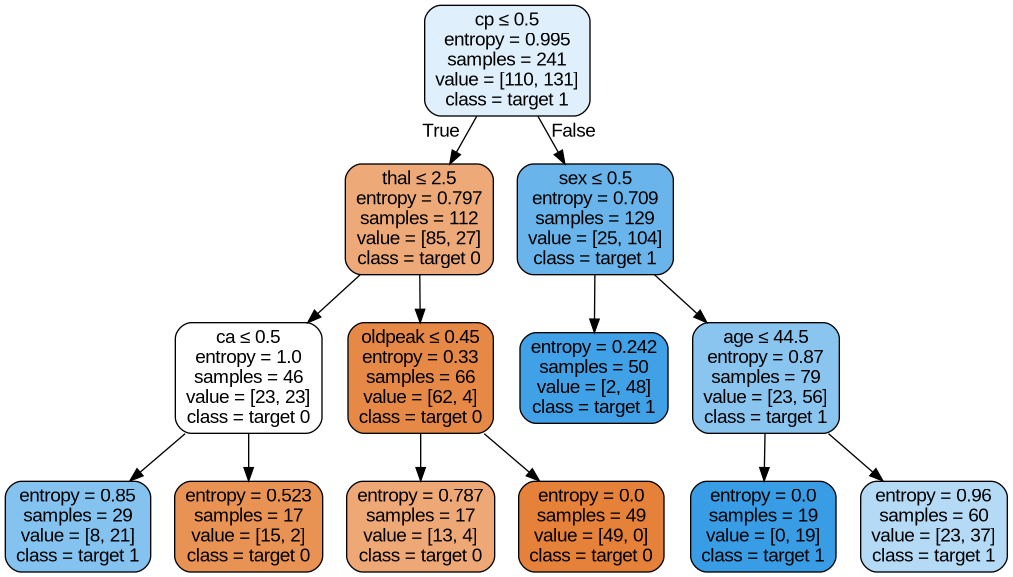

In [13]:
# Graphviz version
dot_data = export_graphviz(dt_tuned, out_file=None, feature_names=features,
                           class_names=["target 0", "target 1"], filled=True, rounded=True,
                           special_characters=True)
with open(f"{OUT}/decision_tree.dot", "w") as f:
    f.write(dot_data)

try:
    import graphviz
    graphviz.Source(dot_data).render(f"{OUT}/07_decision_tree_graphviz", format="png", cleanup=True)
    display(Image(f"{OUT}/07_decision_tree_graphviz.png"))
except Exception as e:
    print("Graphviz rendering not available here (", type(e).__name__, "). The .dot file was still saved;",
          "the Matplotlib tree above shows the same model.")

In [14]:
# Plain-text rules of the tuned tree (handy for reading and for the README)
rules = export_text(dt_tuned, feature_names=features)
with open(f"{OUT}/decision_tree_rules.txt", "w") as f:
    f.write(rules)
print(rules)

|--- cp <= 0.50
|   |--- thal <= 2.50
|   |   |--- ca <= 0.50
|   |   |   |--- class: 1
|   |   |--- ca >  0.50
|   |   |   |--- class: 0
|   |--- thal >  2.50
|   |   |--- oldpeak <= 0.45
|   |   |   |--- class: 0
|   |   |--- oldpeak >  0.45
|   |   |   |--- class: 0
|--- cp >  0.50
|   |--- sex <= 0.50
|   |   |--- class: 1
|   |--- sex >  0.50
|   |   |--- age <= 44.50
|   |   |   |--- class: 1
|   |   |--- age >  44.50
|   |   |   |--- class: 1



## 9. Entropy & Information Gain (worked example)

For a node with class proportions $p_i$:

$$\text{Entropy} = -\sum_i p_i \log_2 p_i \qquad\qquad \text{Gini} = 1 - \sum_i p_i^2$$

A split sends samples to a left and a right child. Its **information gain** is the drop in entropy:

$$IG = H(\text{parent}) - \left(\frac{n_L}{n}H(\text{left}) + \frac{n_R}{n}H(\text{right})\right)$$

The tree picks, at every node, the split with the highest gain (or the biggest Gini decrease). Let us compute it by hand for the root split and compare with scikit-learn.

In [15]:
def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def gini(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    return float(1 - (p ** 2).sum())

def info_gain(labels, left_mask):
    n = len(labels)
    left, right = labels[left_mask], labels[~left_mask]
    return entropy(labels) - len(left) / n * entropy(left) - len(right) / n * entropy(right)

y_arr = y_train.values
print("Parent entropy: %.4f | parent gini: %.4f" % (entropy(y_arr), gini(y_arr)))

# Best root split according to scikit-learn (entropy criterion, depth-1 tree = a "stump")
stump = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=RS).fit(X_train, y_train)
f_idx, thr = stump.tree_.feature[0], stump.tree_.threshold[0]
mask = (X_train.iloc[:, f_idx] <= thr).values
print(f"\nRoot split chosen by sklearn: {features[f_idx]} <= {thr:.2f}")
print("Information gain (by hand)   : %.4f" % info_gain(y_arr, mask))

t = stump.tree_
n = t.n_node_samples
sk_gain = t.impurity[0] - n[1] / n[0] * t.impurity[1] - n[2] / n[0] * t.impurity[2]
print("Information gain (sklearn)   : %.4f" % sk_gain)

Parent entropy: 0.9945 | parent gini: 0.4962

Root split chosen by sklearn: cp <= 0.50
Information gain (by hand)   : 0.2445
Information gain (sklearn)   : 0.2445


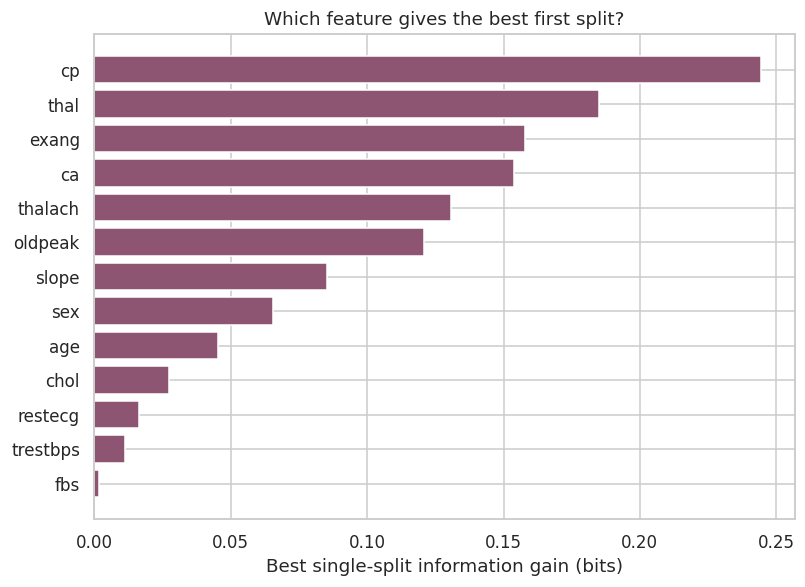

In [16]:
# Best information gain achievable by each feature (try every possible threshold)
best_gain = {}
for col in features:
    vals = np.sort(X_train[col].unique())
    thresholds = (vals[:-1] + vals[1:]) / 2
    gains = [info_gain(y_arr, (X_train[col] <= th).values) for th in thresholds]
    best_gain[col] = max(gains) if gains else 0.0
gain_s = pd.Series(best_gain).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(gain_s.index, gain_s.values, color=C_ACC)
ax.set_xlabel("Best single-split information gain (bits)")
ax.set_title("Which feature gives the best first split?")
plt.tight_layout()
plt.savefig(f"{OUT}/08_information_gain_per_feature.png", bbox_inches="tight")
plt.show()

## 10. Random Forest & Model Comparison

A **Random Forest** trains many decision trees, each on a different **bootstrap sample** of the rows (bagging) and with a random subset of features considered at every split. Predictions are averaged (voting). Individual trees overfit in different ways, and averaging cancels much of that noise, so variance drops while bias stays low.

In [17]:
rf_default = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=RS, n_jobs=-1).fit(X_train, y_train)

rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, oob_score=True, random_state=RS, n_jobs=-1),
    {"max_depth": [None, 4, 6, 8], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.5]},
    cv=skf5, scoring="accuracy", n_jobs=1).fit(X_train, y_train)
rf_tuned = rf_grid.best_estimator_

print("Random Forest (default) -> train: %.4f | test: %.4f | OOB: %.4f" %
      (rf_default.score(X_train, y_train), rf_default.score(X_test, y_test), rf_default.oob_score_))
print("Random Forest (tuned)   -> train: %.4f | test: %.4f | OOB: %.4f" %
      (rf_tuned.score(X_train, y_train), rf_tuned.score(X_test, y_test), rf_tuned.oob_score_))
print("Best RF params:", rf_grid.best_params_)

Random Forest (default) -> train: 1.0000 | test: 0.7869 | OOB: 0.8299
Random Forest (tuned)   -> train: 1.0000 | test: 0.7705 | OOB: 0.8382
Best RF params: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1}


In [18]:
models = {
    "Decision Tree (unrestricted)": dt_full,
    "Decision Tree (tuned)": dt_tuned,
    "Random Forest (default)": rf_default,
    "Random Forest (tuned)": rf_tuned,
}
rows, probas = [], {}
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    probas[name] = proba
    rows.append({"model": name,
                 "train_acc": m.score(X_train, y_train),
                 "test_acc": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred),
                 "roc_auc": roc_auc_score(y_test, proba)})
comp = pd.DataFrame(rows).set_index("model").round(4)
comp

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
Decision Tree (unrestricted),1.0000,0.8033,0.8182,0.8182,0.8182,0.8019
Decision Tree (tuned),0.8382,0.7705,0.7436,0.8788,0.8056,0.8263
Random Forest (default),1.0000,0.7869,0.8125,0.7879,0.8000,0.8658
Random Forest (tuned),1.0000,0.7705,0.7879,0.7879,0.7879,0.8680


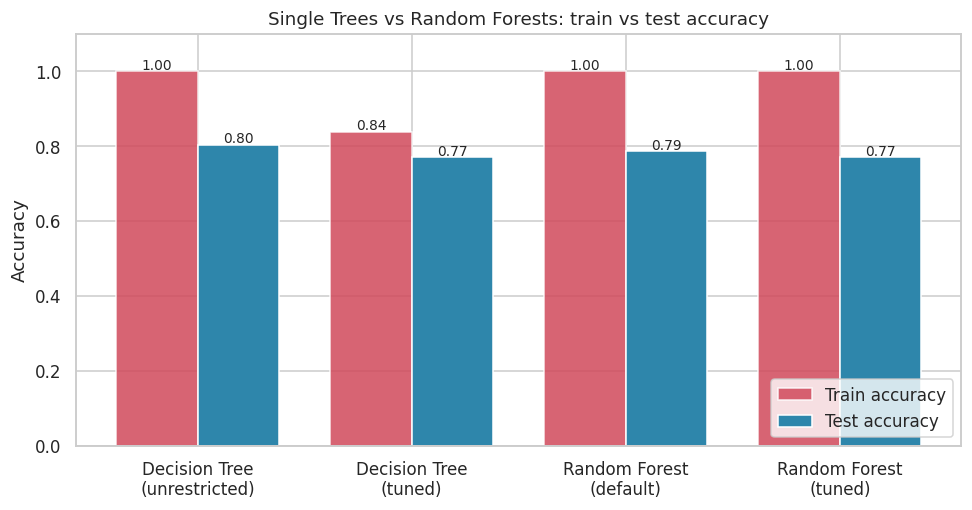

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(comp)); w = 0.38
ax.bar(x - w / 2, comp["train_acc"], w, label="Train accuracy", color=C_RED, alpha=.85)
ax.bar(x + w / 2, comp["test_acc"], w, label="Test accuracy", color=C_DT)
for i, (a, b) in enumerate(zip(comp["train_acc"], comp["test_acc"])):
    ax.text(i - w / 2, a + .005, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + w / 2, b + .005, f"{b:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in comp.index])
ax.set_ylim(0, 1.1); ax.set_ylabel("Accuracy")
ax.set_title("Single Trees vs Random Forests: train vs test accuracy")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT}/09_model_comparison.png", bbox_inches="tight")
plt.show()

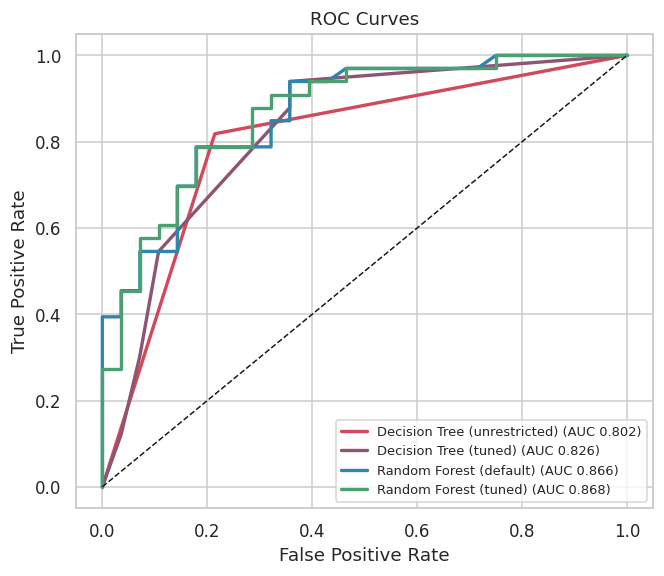

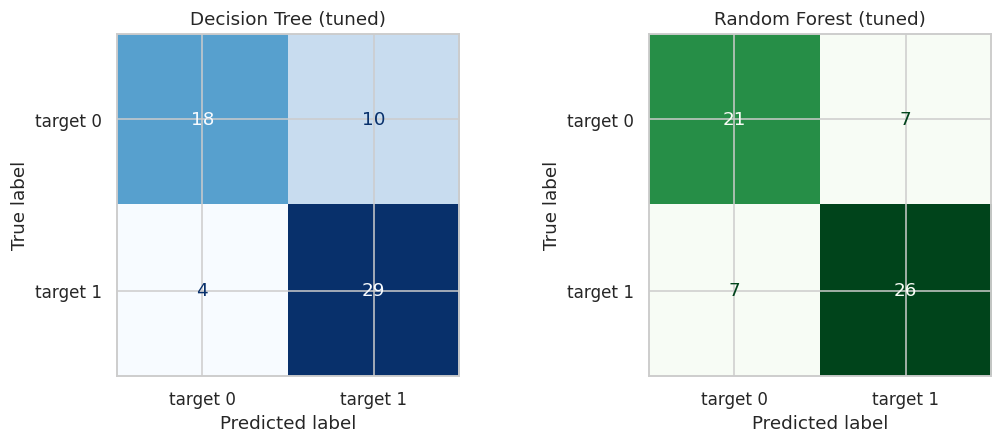

In [20]:
fig, ax = plt.subplots(figsize=(6.2, 5.4))
palette = [C_RED, C_ACC, C_DT, C_RF]
for (name, p), c in zip(probas.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2.2, color=c, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.savefig(f"{OUT}/10_roc_comparison.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, m), cmap in zip(axes, [("Decision Tree (tuned)", dt_tuned), ("Random Forest (tuned)", rf_tuned)], ["Blues", "Greens"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=["target 0", "target 1"]).plot(
        ax=ax, cmap=cmap, colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{OUT}/11_confusion_matrices.png", bbox_inches="tight")
plt.show()

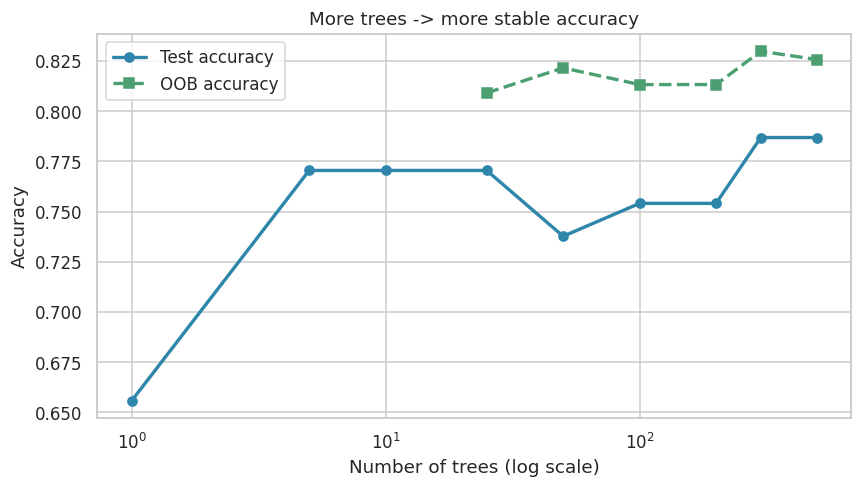

,n_estimators,test,oob
0,1,0.6557,NaN
1,5,0.7705,NaN
2,10,0.7705,NaN
3,25,0.7705,0.8091
4,50,0.7377,0.8216
5,100,0.7541,0.8133
6,200,0.7541,0.8133
7,300,0.7869,0.8299
8,500,0.7869,0.8257


In [21]:
# How many trees are enough?  Test accuracy and out-of-bag (OOB) accuracy vs n_estimators
rows = []
for n in [1, 5, 10, 25, 50, 100, 200, 300, 500]:
    m = RandomForestClassifier(n_estimators=n, oob_score=(n >= 25), random_state=RS, n_jobs=-1).fit(X_train, y_train)
    rows.append({"n_estimators": n, "test": m.score(X_test, y_test), "oob": m.oob_score_ if n >= 25 else np.nan})
ne_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(ne_df["n_estimators"], ne_df["test"], "o-", color=C_DT, lw=2.2, label="Test accuracy")
ax.plot(ne_df["n_estimators"], ne_df["oob"], "s--", color=C_RF, lw=2.2, label="OOB accuracy")
ax.set_xscale("log"); ax.set_xlabel("Number of trees (log scale)"); ax.set_ylabel("Accuracy")
ax.set_title("More trees -> more stable accuracy")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/12_trees_vs_accuracy.png", bbox_inches="tight")
plt.show()
ne_df.round(4)

## 11. Feature Importance

Two complementary views:
- **Impurity-based importance** (`feature_importances_`): how much each feature reduced impurity across all splits. Fast, but biased toward continuous / high-cardinality features and computed on training data.
- **Permutation importance**: how much the *test* score drops when a feature's values are shuffled. Slower, but model-agnostic and measured on unseen data.

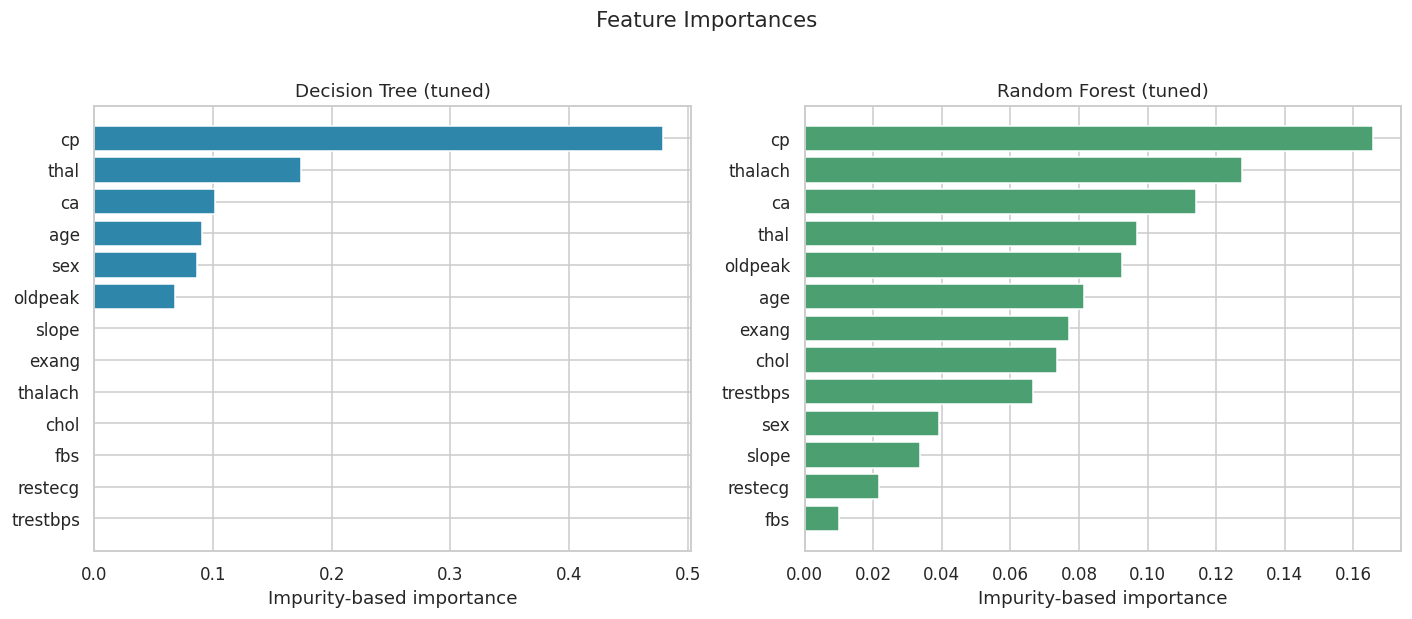

Top 5 features (Random Forest):
cp         0.1657
thalach    0.1276
ca         0.1141
thal       0.0970
oldpeak    0.0925


In [22]:
imp_df = pd.DataFrame({"Decision Tree (tuned)": dt_tuned.feature_importances_,
                       "Random Forest (tuned)": rf_tuned.feature_importances_}, index=features)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=False)
for ax, col, color in zip(axes, imp_df.columns, [C_DT, C_RF]):
    s = imp_df[col].sort_values()
    ax.barh(s.index, s.values, color=color)
    ax.set_title(col); ax.set_xlabel("Impurity-based importance")
plt.suptitle("Feature Importances", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUT}/13_feature_importance.png", bbox_inches="tight")
plt.show()

print("Top 5 features (Random Forest):")
print(imp_df["Random Forest (tuned)"].sort_values(ascending=False).head(5).round(4).to_string())

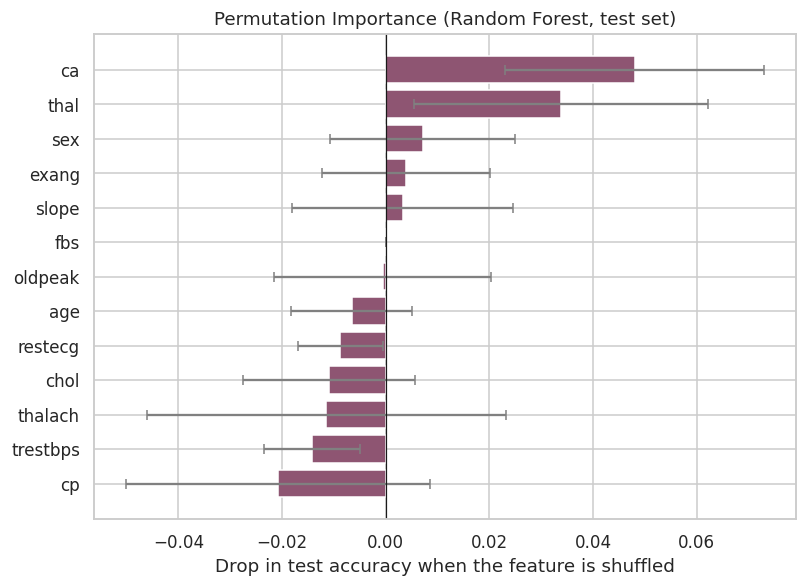

Top 5 by permutation importance:
ca       0.0481
thal     0.0339
sex      0.0071
exang    0.0038
slope    0.0033


In [23]:
perm = permutation_importance(rf_tuned, X_test, y_test, n_repeats=30, random_state=RS, n_jobs=-1, scoring="accuracy")
perm_df = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=features).sort_values("mean")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(perm_df.index, perm_df["mean"], xerr=perm_df["std"], color=C_ACC, ecolor="gray", capsize=3)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Drop in test accuracy when the feature is shuffled")
ax.set_title("Permutation Importance (Random Forest, test set)")
plt.tight_layout()
plt.savefig(f"{OUT}/14_permutation_importance.png", bbox_inches="tight")
plt.show()

print("Top 5 by permutation importance:")
print(perm_df["mean"].sort_values(ascending=False).head(5).round(4).to_string())

**How to read it:** features at the top are the ones the model relies on most. If impurity-based and permutation rankings agree, you can trust the story; if they disagree, prefer permutation importance. Importance tells you what the *model* uses, not that a feature *causes* the outcome. Correlated features also share (and therefore dilute) their importance.

## 12. Cross-Validation

One train/test split can be lucky or unlucky, especially on a small dataset. We therefore compare the models with **repeated stratified 5-fold cross-validation** (5 folds x 3 repeats = 15 scores per model) on the full dataset.

,accuracy,f1,roc_auc
model,,,
Decision Tree (unrestricted),0.7658 ± 0.0562,0.7842 ± 0.0557,0.7638 ± 0.0557
Decision Tree (tuned),0.7746 ± 0.0629,0.8003 ± 0.0545,0.8364 ± 0.0544
Random Forest (default),0.8178 ± 0.0380,0.8362 ± 0.0361,0.9011 ± 0.0258
Random Forest (tuned),0.8233 ± 0.0407,0.8411 ± 0.0385,0.9038 ± 0.0245


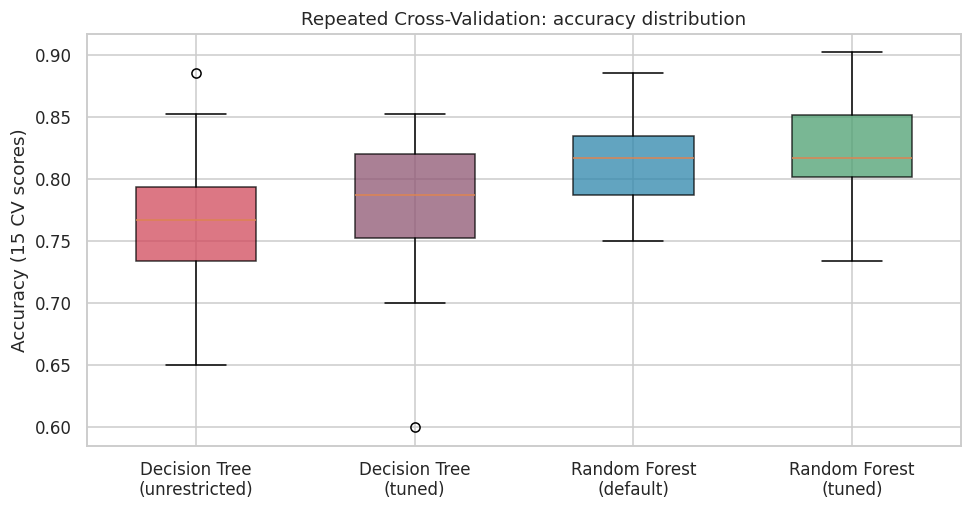

In [24]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
cv_models = {
    "Decision Tree\n(unrestricted)": DecisionTreeClassifier(random_state=RS),
    "Decision Tree\n(tuned)": clone(dt_tuned),
    "Random Forest\n(default)": RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
    "Random Forest\n(tuned)": clone(rf_tuned),
}
cv_scores, cv_rows = {}, []
for name, m in cv_models.items():
    res = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=1)
    cv_scores[name] = res["test_accuracy"]
    cv_rows.append({"model": name.replace("\n", " "),
                    "accuracy": f"{res['test_accuracy'].mean():.4f} ± {res['test_accuracy'].std():.4f}",
                    "f1": f"{res['test_f1'].mean():.4f} ± {res['test_f1'].std():.4f}",
                    "roc_auc": f"{res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}",
                    "_acc_mean": res["test_accuracy"].mean(), "_acc_std": res["test_accuracy"].std(),
                    "_f1_mean": res["test_f1"].mean(), "_auc_mean": res["test_roc_auc"].mean()})
cv_df = pd.DataFrame(cv_rows)
display(cv_df[["model", "accuracy", "f1", "roc_auc"]].set_index("model"))

fig, ax = plt.subplots(figsize=(9, 4.8))
bp = ax.boxplot(list(cv_scores.values()), patch_artist=True, widths=.55)
ax.set_xticklabels(list(cv_scores.keys()))
for patch, c in zip(bp["boxes"], [C_RED, C_ACC, C_DT, C_RF]):
    patch.set_facecolor(c); patch.set_alpha(.75)
ax.set_ylabel("Accuracy (15 CV scores)")
ax.set_title("Repeated Cross-Validation: accuracy distribution")
plt.tight_layout()
plt.savefig(f"{OUT}/15_cv_boxplot.png", bbox_inches="tight")
plt.show()

**Note:** the "tuned" hyperparameters were chosen on the training split, which overlaps with the CV folds, so the tuned scores are slightly optimistic. For a fully unbiased estimate you would use *nested* cross-validation.

## 13. Bonus: Trees for Regression

Tree models also work for regression: each leaf predicts the **average target value** of the samples that reach it. Here we predict a patient's **maximum heart rate (`thalach`)** from the other measurements.

,R2 (test),RMSE (test),MAE (test),R2 (5-fold CV)
model,,,,
Decision Tree (unrestricted),-0.688,28.064,20.951,-0.291
Decision Tree (depth 3),0.302,18.041,14.134,0.355
Random Forest,0.250,18.710,14.406,0.370


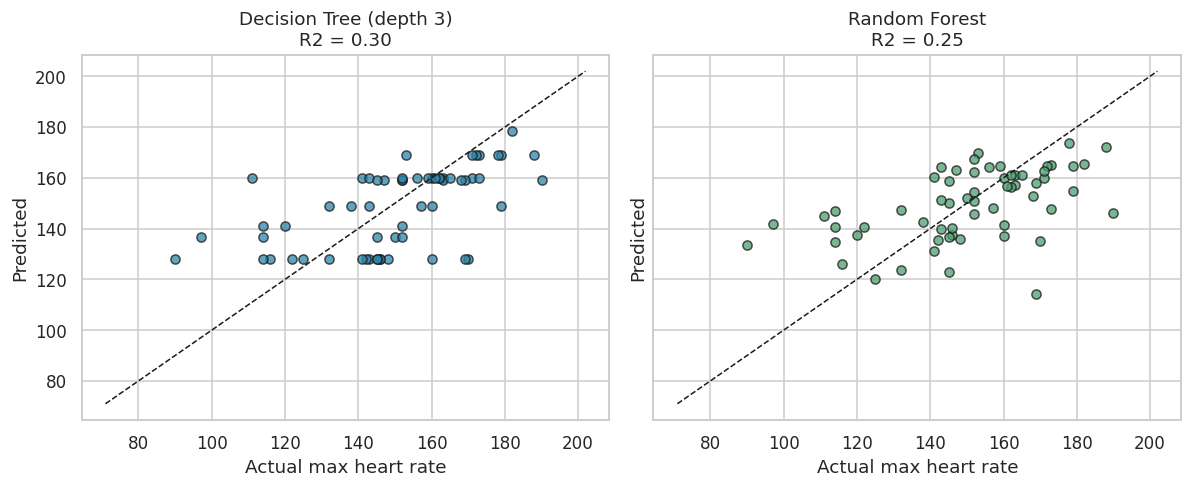

In [25]:
Xr, yr = df.drop(columns=["thalach", "target"]), df["thalach"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RS)

reg_models = {
    "Decision Tree (unrestricted)": DecisionTreeRegressor(random_state=RS),
    "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=RS),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RS, n_jobs=-1),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RS)
rows, reg_preds = [], {}
for name, m in reg_models.items():
    m.fit(Xr_tr, yr_tr)
    p = m.predict(Xr_te); reg_preds[name] = p
    rows.append({"model": name,
                 "R2 (test)": r2_score(yr_te, p),
                 "RMSE (test)": mean_squared_error(yr_te, p) ** 0.5,
                 "MAE (test)": mean_absolute_error(yr_te, p),
                 "R2 (5-fold CV)": cross_val_score(clone(m), Xr, yr, cv=kf, scoring="r2").mean()})
reg_df = pd.DataFrame(rows).set_index("model").round(3)
display(reg_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, c in zip(axes, ["Decision Tree (depth 3)", "Random Forest"], [C_DT, C_RF]):
    ax.scatter(yr_te, reg_preds[name], color=c, edgecolor="k", alpha=.75)
    lo, hi = yr.min(), yr.max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(f"{name}\nR2 = {r2_score(yr_te, reg_preds[name]):.2f}")
    ax.set_xlabel("Actual max heart rate"); ax.set_ylabel("Predicted")
plt.tight_layout()
plt.savefig(f"{OUT}/16_regression_results.png", bbox_inches="tight")
plt.show()

## 14. Key Concepts: Questions & Answers

**1. How does a decision tree work?**
It repeatedly asks a yes/no question about one feature (`feature <= threshold`). At each node it tries many candidate splits and keeps the one that makes the child nodes purest (largest drop in Gini impurity or entropy). It recurses until a stopping rule is hit (pure node, `max_depth`, `min_samples_leaf`...). A prediction follows the path of answers down to a leaf: the majority class (classification) or the average value (regression).

**2. What is entropy and information gain?**
Entropy `H = -sum(p_i * log2 p_i)` measures how mixed a node is: 0 for a pure node, 1 bit for a 50/50 binary node. Information gain is the entropy of the parent minus the weighted entropy of the children after a split. The tree picks the split with the highest gain. Gini impurity `1 - sum(p_i^2)` is a cheaper alternative that usually gives very similar trees.

**3. How is a random forest better than a single tree?**
A single deep tree has low bias but high variance: small changes in the data change the tree a lot, and it overfits. A random forest averages many decorrelated trees (different bootstrap samples and random feature subsets), which cuts variance, so it generalizes better and is more stable, as seen in the cross-validation boxplot.

**4. What is overfitting and how do you prevent it?**
Overfitting is when a model memorises noise in the training data: near-perfect training score, much worse test score. For trees: limit `max_depth`, raise `min_samples_leaf` / `min_samples_split`, prune with `ccp_alpha`, use cross-validation to pick these values, or switch to an ensemble like a random forest. More data and removing duplicates / leakage also help.

**5. What is bagging?**
Bagging (bootstrap aggregating) trains each model on a random sample of the data drawn *with replacement*, then combines them by voting (classification) or averaging (regression). Each bootstrap leaves out about 36% of rows (the *out-of-bag* samples), which gives a free validation estimate (`oob_score_`). A random forest is bagging plus random feature selection at each split.

**6. How do you visualize a decision tree?**
`sklearn.tree.plot_tree` (Matplotlib), `export_graphviz` + Graphviz (`dot` file rendered to PNG/PDF, used in this notebook), `export_text` for plain-text rules, or third-party tools like `dtreeviz`.

**7. How do you interpret feature importance?**
Impurity-based `feature_importances_` sums how much each feature reduced impurity (normalised to 1): fast but biased toward continuous or high-cardinality features. Permutation importance measures the score drop when a feature is shuffled on held-out data: more reliable. Importance shows what the model *uses*, not causation, and correlated features split their importance.

**8. What are the pros/cons of random forests?**
*Pros:* strong accuracy out of the box, handles non-linear relationships and mixed feature types, needs no scaling, robust to outliers, resists overfitting, gives OOB error and feature importances.
*Cons:* less interpretable than one tree, slower and heavier on memory with many trees, can still be biased on very imbalanced data, and does not extrapolate beyond the range seen in training (for regression).

## 15. Save Results & Final Summary

In [26]:
# Save cleaned dataset + metrics for the GitHub project
df.to_csv(f"{OUT}/heart_disease_clean.csv", index=False)

def clean(o):
    if hasattr(o, "item"): return o.item()
    return str(o)

final = {
    "data_source": DATA_SOURCE,
    "n_samples_after_dedup": int(len(df)), "duplicates_removed": n_dup, "n_features": len(features),
    "random_state": RS, "test_size": 0.2,
    "best_depth_by_cv": best_depth, "best_ccp_alpha_by_cv": best_alpha,
    "decision_tree_best_params": dt_grid.best_params_,
    "random_forest_best_params": rf_grid.best_params_,
    "test_comparison": comp.reset_index().to_dict(orient="records"),
    "cross_validation": cv_df[["model", "accuracy", "f1", "roc_auc"]].to_dict(orient="records"),
    "rf_oob_accuracy": round(float(rf_tuned.oob_score_), 4),
    "top_features_rf_impurity": imp_df["Random Forest (tuned)"].sort_values(ascending=False).head(5).round(4).to_dict(),
    "top_features_permutation": perm_df["mean"].sort_values(ascending=False).head(5).round(4).to_dict(),
    "regression_thalach": reg_df.reset_index().to_dict(orient="records"),
}
with open(f"{OUT}/metrics.json", "w") as f:
    json.dump(final, f, indent=2, default=clean)

best_cv = cv_df.loc[cv_df["_acc_mean"].idxmax()]
print("=" * 64)
print("FINAL SUMMARY")
print("=" * 64)
print(f"Dataset            : Heart Disease ({len(df)} unique samples, {len(features)} features)")
print(f"Unrestricted tree  : train {dt_full.score(X_train, y_train):.3f} | test {dt_full.score(X_test, y_test):.3f}  (overfits)")
print(f"Tuned tree         : train {dt_tuned.score(X_train, y_train):.3f} | test {dt_tuned.score(X_test, y_test):.3f}")
print(f"Random forest      : train {rf_tuned.score(X_train, y_train):.3f} | test {rf_tuned.score(X_test, y_test):.3f} | OOB {rf_tuned.oob_score_:.3f}")
print(f"Best model in CV   : {best_cv['model']} -> {best_cv['accuracy']}")
print("Top features (RF)  :", ", ".join(imp_df['Random Forest (tuned)'].sort_values(ascending=False).head(4).index))
print("=" * 64)
print("Files saved in:", OUT)
print(sorted(os.listdir(OUT)))

FINAL SUMMARY
Dataset            : Heart Disease (302 unique samples, 13 features)
Unrestricted tree  : train 1.000 | test 0.803  (overfits)
Tuned tree         : train 0.838 | test 0.770
Random forest      : train 1.000 | test 0.770 | OOB 0.838
Best model in CV   : Random Forest (tuned) -> 0.8233 ± 0.0407
Top features (RF)  : cp, thalach, ca, thal
Files saved in: /kaggle/working
['.virtual_documents', '01_class_distribution.png', '02_correlation_heatmap.png', '03_unrestricted_tree_top_levels.png', '04_overfitting_vs_depth.png', '05_pruning_path.png', '06_tuned_tree_matplotlib.png', '07_decision_tree_graphviz.png', '08_information_gain_per_feature.png', '09_model_comparison.png', '10_roc_comparison.png', '11_confusion_matrices.png', '12_trees_vs_accuracy.png', '13_feature_importance.png', '14_permutation_importance.png', '15_cv_boxplot.png', '16_regression_results.png', 'decision_tree.dot', 'decision_tree_rules.txt', 'heart_disease_clean.csv', 'metrics.json']
